# Ranodom Imputation 

missing values filled by on fo the value on the data column 


## Advantages 
 statastics remain uneffected 
 distribution ofthe data is almost  intact -> variance remains almost same 


 ## works best with linear algorithms rather then decision tree 


## Disadntages 
 it is memory heavy as u haveto to keep the test data   

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"E:\MACHINE_LEARNING\Day_38\datasets\train.csv" , usecols= ['Age','Fare','Survived'] )


In [3]:
df.isnull().mean() * 100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [4]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [19]:
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [20]:
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna()
    .sample(X_train['Age'].isnull().sum())
    .values
)

X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = (
    X_train['Age'].dropna()
    .sample(X_test['Age'].isnull().sum())
    .values
)

In [11]:
X_train.isnull().sum()

Age             148
Fare              0
Age_imputed     148
Fare_imputed      0
dtype: int64

C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\2642582470.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'],label='Original',hist=False)
C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\2642582470.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[

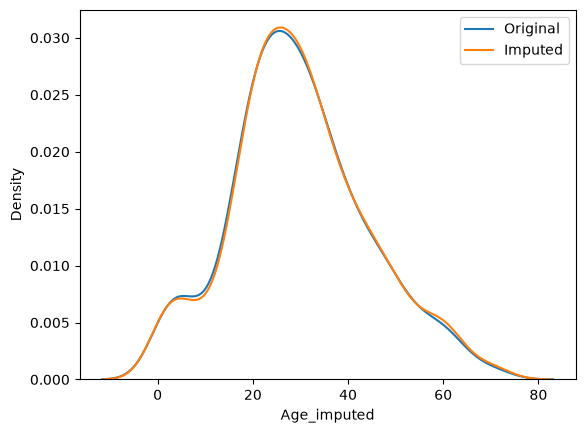

In [25]:
sns.distplot(X_train['Age'],label='Original',hist=False)
sns.distplot(X_train['Age_imputed'],label = 'Imputed',hist=False)

plt.legend()
plt.show()

In [31]:
X_train['Age'].var() , X_train['Age_imputed'].var()

# a


TypeError: Series.cov() missing 1 required positional argument: 'other'

In [32]:
X_train.cov()

,Age,Fare,Age_imputed,Fare_imputed
Age,204.349513,71.512440,204.349513,71.512440
Fare,71.512440,2368.246832,59.901823,2368.246832
Age_imputed,204.349513,59.901823,208.109501,59.901823
Fare_imputed,71.512440,2368.246832,59.901823,2368.246832


<Axes: >

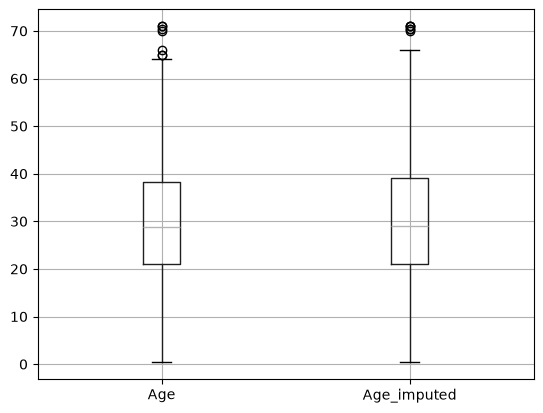

In [33]:
X_train[['Age', 'Age_imputed']].boxplot()

In [35]:
data = pd.read_csv(r"E:\MACHINE_LEARNING\Day_38\datasets\house-train.csv" , usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [37]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [39]:
X = data
y = data['SalePrice']

In [40]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [53]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [54]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
130,Gd,TA,226000,TA,Gd
694,NaN,TA,141500,TA,NaN
250,NaN,NaN,76500,NaN,NaN
665,TA,TA,230500,TA,TA
559,TA,TA,234000,TA,TA


In [55]:
# GarageQual - Training data
X_train.loc[
    X_train['GarageQual_imputed'].isnull(),
    'GarageQual_imputed'
] = (
    X_train['GarageQual'].dropna()
    .sample(X_train['GarageQual'].isnull().sum(), random_state=42)
    .values
)

# GarageQual - Testing data
X_test.loc[
    X_test['GarageQual_imputed'].isnull(),
    'GarageQual_imputed'
] = (
    X_train['GarageQual'].dropna()
    .sample(X_test['GarageQual'].isnull().sum(), random_state=42)
    .values
)


# FireplaceQu - Training data
X_train.loc[
    X_train['FireplaceQu_imputed'].isnull(),
    'FireplaceQu_imputed'
] = (
    X_train['FireplaceQu'].dropna()
    .sample(X_train['FireplaceQu'].isnull().sum(), random_state=42)
    .values
)

# FireplaceQu - Testing data
X_test.loc[
    X_test['FireplaceQu_imputed'].isnull(),
    'FireplaceQu_imputed'
] = (
    X_train['FireplaceQu'].dropna()
    .sample(X_test['FireplaceQu'].isnull().sum(), random_state=42)
    .values
)

In [59]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']
temp

,original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [60]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.655443
TA,0.412439,0.533109
Fa,0.040917,0.052750
Po,0.027823,0.037037
Ex,0.024550,0.032548


C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\1827688635.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\1827688635.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457a

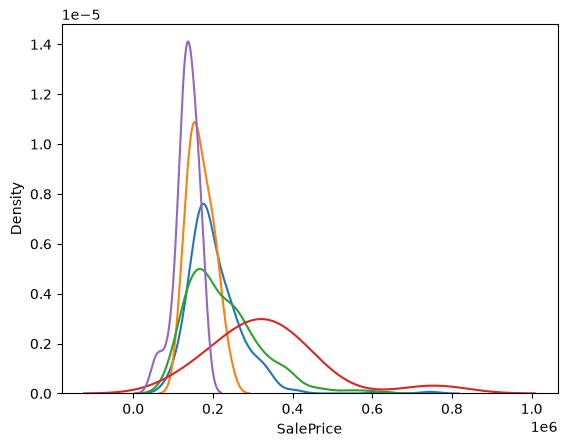

In [62]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],hist=False,label=category)
plt.show()

C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\722808554.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],hist=False,label=category)
C:\Users\saumi\AppData\Local\Temp\ipykernel_33420\722808554.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed29

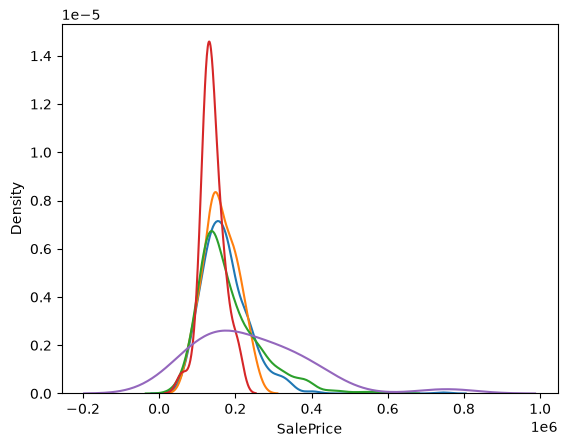

In [61]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'],hist=False,label=category)
plt.show()